
# **🍽️ Restaurant Analysis System**

Using Data Science to Decode Restaurant Success in Bengaluru

---







### **Project Objective**

The objective of this project is to analyze restaurant data from Bengaluru and identify the key factors that contribute to restaurant success.

Using Python-based data analytics and visualization techniques, the project explores customer ratings, pricing patterns, cuisines, restaurant types, locations, and online ordering behavior.

### **Business Question**

Can data reveal the hidden formula behind a successful restaurant?



---



# 📂 Dataset Overview

Dataset: Zomato Bengaluru Restaurants Dataset

Source: Kaggle

Dataset Size:
- 51,717 restaurant records
- 17 features

Key Attributes:
- Restaurant Name
- Rating
- Votes
- Cost for Two
- Cuisine Type
- Location
- Online Ordering Availability
- Restaurant Type

This dataset was selected because it contains rich real-world information suitable for business analytics and data visualization.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/zomato.csv")

In [ ]:
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [ ]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='object')

In [ ]:
df.dtypes

,0
url,object
address,object
name,object
online_order,object
book_table,object
rate,object
votes,int64
phone,object
location,object
rest_type,object


In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
dish_liked,28078
rate,7775
phone,1208
approx_cost(for two people),346
rest_type,227
cuisines,45
location,21
url,0
address,0
votes,0


# 🧹 Data Cleaning & Preprocessing

Real-world datasets often contain missing values, inconsistent formats, and text-based numerical information. Before performing any analysis, the dataset must be cleaned and transformed into a structured format suitable for statistical analysis and visualization.

The following preprocessing steps were performed:
- Missing value analysis
- Rating column cleaning
- Cost column cleaning
- Handling null values
- Feature standardization

In [ ]:
df = df.drop(['url', 'phone'], axis=1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   address                      51717 non-null  object
 1   name                         51717 non-null  object
 2   online_order                 51717 non-null  object
 3   book_table                   51717 non-null  object
 4   rate                         43942 non-null  object
 5   votes                        51717 non-null  int64 
 6   location                     51696 non-null  object
 7   rest_type                    51490 non-null  object
 8   dish_liked                   23639 non-null  object
 9   cuisines                     51672 non-null  object
 10  approx_cost(for two people)  51371 non-null  object
 11  reviews_list                 51717 non-null  object
 12  menu_item                    51717 non-null  object
 13  listed_in(type)              51

### Cleaning the Rating Column

The rating column contained values such as "4.1/5", "NEW", and "-". These values cannot be used directly for numerical analysis. Therefore, the ratings were cleaned, converted into numeric format, and invalid entries were handled appropriately.


In [ ]:
df['rate'].unique()

array(['4.1/5', '3.8/5', '3.7/5', '3.6/5', '4.6/5', '4.0/5', '4.2/5',
       '3.9/5', '3.1/5', '3.0/5', '3.2/5', '3.3/5', '2.8/5', '4.4/5',
       '4.3/5', 'NEW', '2.9/5', '3.5/5', nan, '2.6/5', '3.8 /5', '3.4/5',
       '4.5/5', '2.5/5', '2.7/5', '4.7/5', '2.4/5', '2.2/5', '2.3/5',
       '3.4 /5', '-', '3.6 /5', '4.8/5', '3.9 /5', '4.2 /5', '4.0 /5',
       '4.1 /5', '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5',
       '3.5 /5', '2.7 /5', '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5',
       '4.3 /5', '4.4 /5', '4.9/5', '2.1/5', '2.0/5', '1.8/5', '4.6 /5',
       '4.9 /5', '3.0 /5', '4.8 /5', '2.3 /5', '4.7 /5', '2.4 /5',
       '2.1 /5', '2.2 /5', '2.0 /5', '1.8 /5'], dtype=object)

In [ ]:
# Remove '/5'
df['rate'] = df['rate'].str.replace('/5', '', regex=False)

# Remove extra spaces
df['rate'] = df['rate'].str.strip()

# Replace invalid values with NaN
df['rate'] = df['rate'].replace(['NEW', '-'], np.nan)

# Convert to numeric
df['rate'] = pd.to_numeric(df['rate'], errors='coerce')

In [ ]:
df['rate'].head()

,rate
0,4.1
1,4.1
2,3.8
3,3.7
4,3.8


In [ ]:
df['rate'].dtype

dtype('float64')

### Missing Value Analysis

The first step was to identify missing values in the dataset. Understanding missing data helps determine which columns require cleaning or further preprocessing before analysis.

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
dish_liked,28078
rate,10052
approx_cost(for two people),346
rest_type,227
cuisines,45
location,21
address,0
votes,0
book_table,0
name,0




---



### Cleaning the Cost Column

The cost column contained values with commas (for example: 1,200 and 2,500).

Since mathematical operations require numerical data types, commas were removed and the column was converted into numeric format.

In [ ]:
df['approx_cost(for two people)'].unique()

array(['800', '300', '600', '700', '550', '500', '450', '650', '400',
       '900', '200', '750', '150', '850', '100', '1,200', '350', '250',
       '950', '1,000', '1,500', '1,300', '199', '80', '1,100', '160',
       '1,600', '230', '130', '50', '190', '1,700', nan, '1,400', '180',
       '1,350', '2,200', '2,000', '1,800', '1,900', '330', '2,500',
       '2,100', '3,000', '2,800', '3,400', '40', '1,250', '3,500',
       '4,000', '2,400', '2,600', '120', '1,450', '469', '70', '3,200',
       '60', '560', '240', '360', '6,000', '1,050', '2,300', '4,100',
       '5,000', '3,700', '1,650', '2,700', '4,500', '140'], dtype=object)

In [ ]:
# Remove commas
df['approx_cost(for two people)'] = df['approx_cost(for two people)'].str.replace(',', '')

# Convert to numeric
df['approx_cost(for two people)'] = pd.to_numeric(
    df['approx_cost(for two people)'],
    errors='coerce'
)

In [ ]:
df['approx_cost(for two people)'].dtype

dtype('float64')



---







In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
dish_liked,28078
rate,10052
approx_cost(for two people),346
rest_type,227
cuisines,45
location,21
address,0
votes,0
book_table,0
name,0


In [ ]:
df['dish_liked'] = df['dish_liked'].fillna('Not Mentioned')

### Handling Missing Values

After cleaning the rating and cost columns, records containing critical missing information were removed. This ensures that subsequent analysis is based on complete and reliable data.

In [ ]:
df = df.dropna(subset=['rate'])

In [ ]:
df = df.dropna(subset=[
    'location',
    'rest_type',
    'cuisines',
    'approx_cost(for two people)'
])

In [ ]:
df.isnull().sum()

,0
address,0
name,0
online_order,0
book_table,0
rate,0
votes,0
location,0
rest_type,0
dish_liked,0
cuisines,0


# ⚙️ Feature Engineering

Feature engineering involves creating new variables from existing data to improve analysis and extract deeper business insights.

Instead of relying solely on the original dataset, additional features were created to better understand restaurant performance and customer behavior.


---



### Creating Price Categories

Restaurants were grouped into Budget, Mid-Range, and Premium categories based on their approximate cost for two people.

This simplifies pricing analysis and allows easier comparison across restaurant segments.

In [ ]:
def categorize_cost(cost):
    if cost <= 500:
        return 'Budget'
    elif cost <= 1500:
        return 'Mid-Range'
    else:
        return 'Premium'

df['price_category'] = df['approx_cost(for two people)'].apply(categorize_cost)

### Creating Rating Categories

Ratings were grouped into categories such as Poor, Average, Good, and Excellent.

This makes customer satisfaction trends easier to understand and visualize.

In [ ]:
def categorize_rating(rate):
    if rate < 3:
        return 'Poor'
    elif rate < 4:
        return 'Average'
    else:
        return 'Excellent'

df['rating_category'] = df['rate'].apply(categorize_rating)

### Creating a Restaurant Success Score

A custom success score was created to estimate restaurant performance by combining customer ratings, popularity (votes), and pricing information.

This metric helps compare restaurants using multiple factors rather than relying on ratings alone.

In [ ]:
df['success_score'] = (df['rate'] * df['votes']) / df['approx_cost(for two people)']

In [ ]:
df[['rate', 'votes', 'success_score']].head()

,rate,votes,success_score
0,4.1,775,3.971875
1,4.1,787,4.033375
2,3.8,918,4.360500
3,3.7,88,1.085333
4,3.8,166,1.051333


In [ ]:
df[['price_category', 'rating_category']].head()

,price_category,rating_category
0,Mid-Range,Excellent
1,Mid-Range,Excellent
2,Mid-Range,Average
3,Budget,Average
4,Mid-Range,Average


# 📊 Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to identify patterns, trends, and relationships within the restaurant dataset. The objective was to answer key business questions related to restaurant performance, customer satisfaction, pricing, cuisines, and location-based trends.

In [ ]:
df[['rate', 'votes', 'approx_cost(for two people)']].describe()

,rate,votes,approx_cost(for two people)
count,41263.000000,41263.000000,41263.000000
mean,3.702011,352.683179,603.914063
std,0.439985,884.177761,464.942973
min,1.800000,0.000000,40.000000
25%,3.400000,21.000000,300.000000
50%,3.700000,73.000000,500.000000
75%,4.000000,277.000000,750.000000
max,4.900000,16832.000000,6000.000000


Relationship between online ordering and ratings.

In [ ]:
df.groupby('online_order')['rate'].mean()

,rate
online_order,
No,3.660031
Yes,3.723947


# **Business Question 1**

What is the overall distribution of restaurant ratings in Bengaluru?

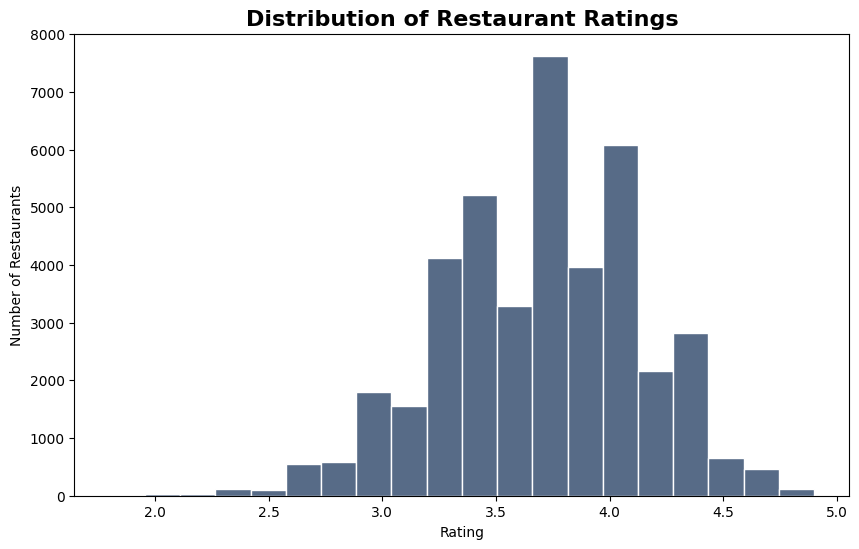

In [ ]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['rate'],
    bins=20,
    color='#1F3A5F',
    edgecolor='white'
)

plt.title(
    'Distribution of Restaurant Ratings',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')

plt.show()

### Observation

Most restaurants are concentrated between ratings of 3.5 and 4.0. Extremely low-rated and extremely high-rated restaurants are relatively rare.

### Business Insight

The majority of restaurants provide a satisfactory customer experience, resulting in average-to-good ratings. The market appears highly competitive, with most businesses performing within a similar rating range.



---



## Business Question 2

Do restaurants that offer online ordering receive better customer ratings?

In [ ]:
df.groupby('online_order')['rate'].mean()

,rate
online_order,
No,3.660031
Yes,3.723947


/tmp/ipykernel_1411/3994380238.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


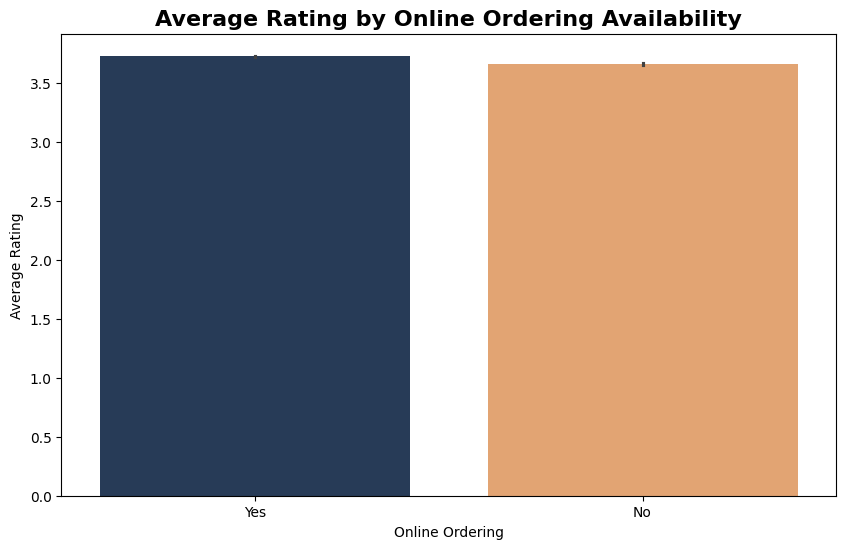

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='online_order',
    y='rate',
    data=df,
    palette=['#1F3A5F', '#F4A261']
)

plt.title(
    'Average Rating by Online Ordering Availability',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Online Ordering')
plt.ylabel('Average Rating')

plt.show()


### Observation

The average ratings of restaurants with and without online ordering are very similar, with only a small difference between the two groups.

### Business Insight

Online ordering alone does not appear to significantly influence customer ratings. Factors such as food quality, service, and customer experience may play a larger role in determining satisfaction.



---



## Business Question 3

Does spending more money lead to higher restaurant ratings?

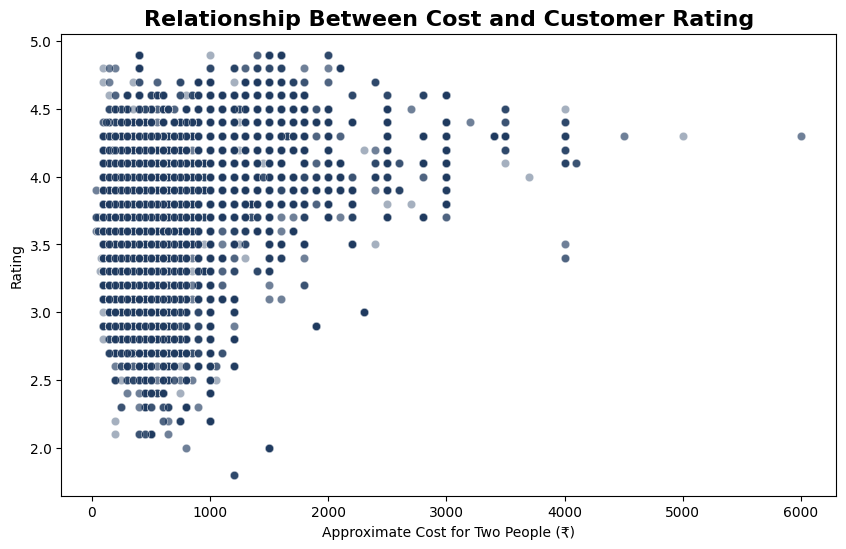

In [ ]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='approx_cost(for two people)',
    y='rate',
    color='#1F3A5F',
    alpha=0.4
)

plt.title(
    'Relationship Between Cost and Customer Rating',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Approximate Cost for Two People (₹)')
plt.ylabel('Rating')

plt.show()


### Observation

Most restaurants, regardless of price range, receive ratings between 3.5 and 4.5. While some expensive restaurants are highly rated, many affordable restaurants also achieve strong ratings.

### Business Insight

Higher pricing does not guarantee higher customer satisfaction. Restaurants can achieve excellent ratings through quality food, service, and customer experience without necessarily charging premium prices.



---



## Business Question 4

How do customer ratings vary across different price categories?

/tmp/ipykernel_1411/3309394366.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


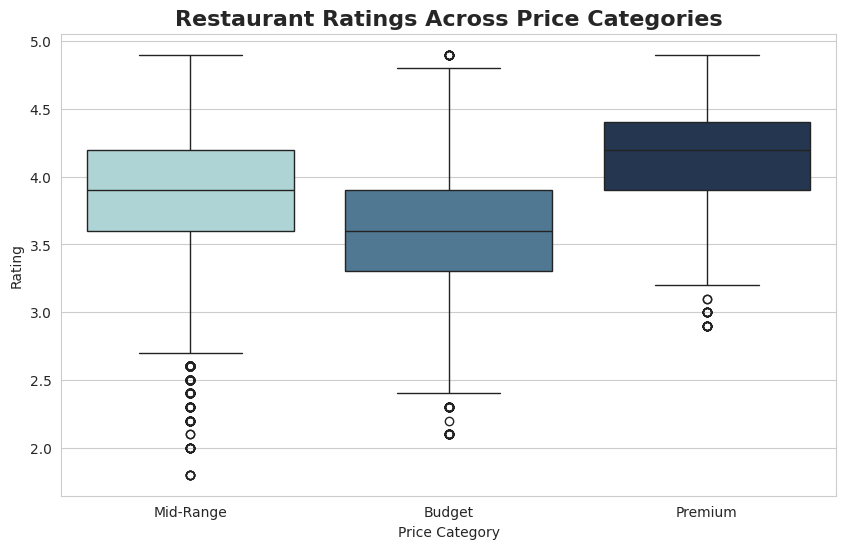

In [ ]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10,6)

plt.figure(figsize=(10,6))

sns.boxplot(
    x='price_category',
    y='rate',
    data=df,
    palette=['#A8DADC', '#457B9D', '#1D3557']
)

plt.title(
    'Restaurant Ratings Across Price Categories',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Price Category')
plt.ylabel('Rating')

plt.show()

### Observation

Most restaurants across all price categories receive ratings between 3.5 and 4.5. Premium restaurants show slightly higher median ratings, but the difference is not substantial.

### Business Insight

Customers evaluate restaurants based on more than just pricing. While premium restaurants may have a slight advantage, affordable restaurants can achieve equally strong customer satisfaction.



---



## Business Question 5

Which cuisines dominate Bengaluru's restaurant market?

/tmp/ipykernel_1411/2452648645.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


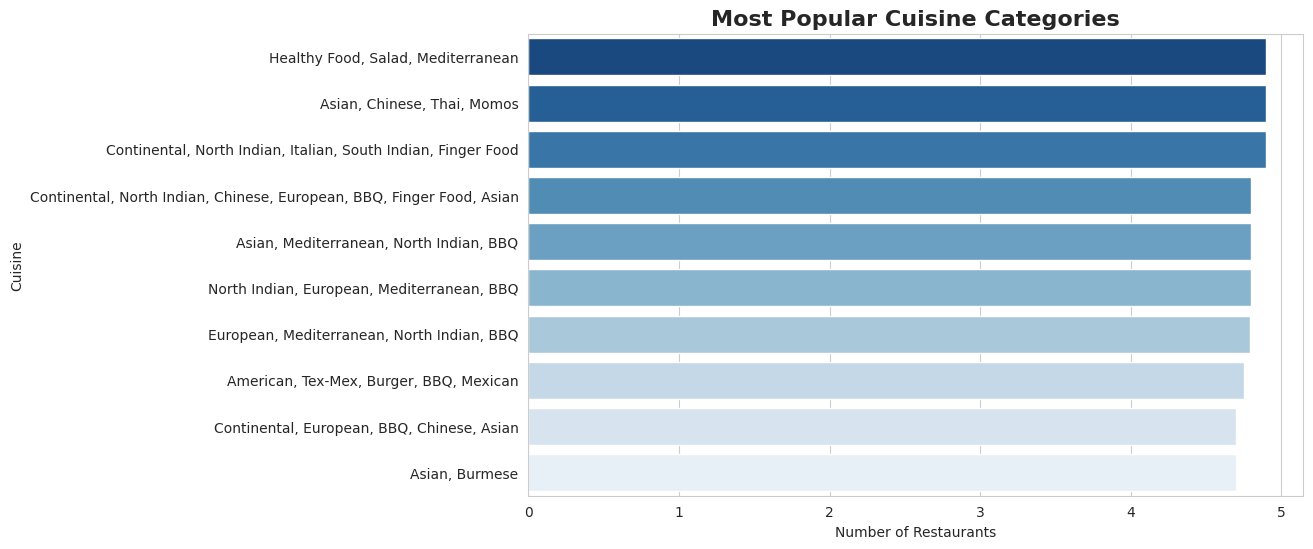

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index,
    palette='Blues_r'
)

plt.title(
    'Most Popular Cuisine Categories',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')

plt.show()

### Observation

North Indian cuisine appears most frequently in the dataset, followed by Chinese and South Indian cuisines. These cuisine categories have a strong presence across Bengaluru.

### Business Insight

The popularity of North Indian cuisine suggests strong customer demand. However, the high number of restaurants in this segment also indicates increased competition for new businesses entering the market.



---



In [ ]:
!pip install wordcloud

## Business Question 6

Which cuisine-related keywords appear most frequently in Bengaluru restaurants?

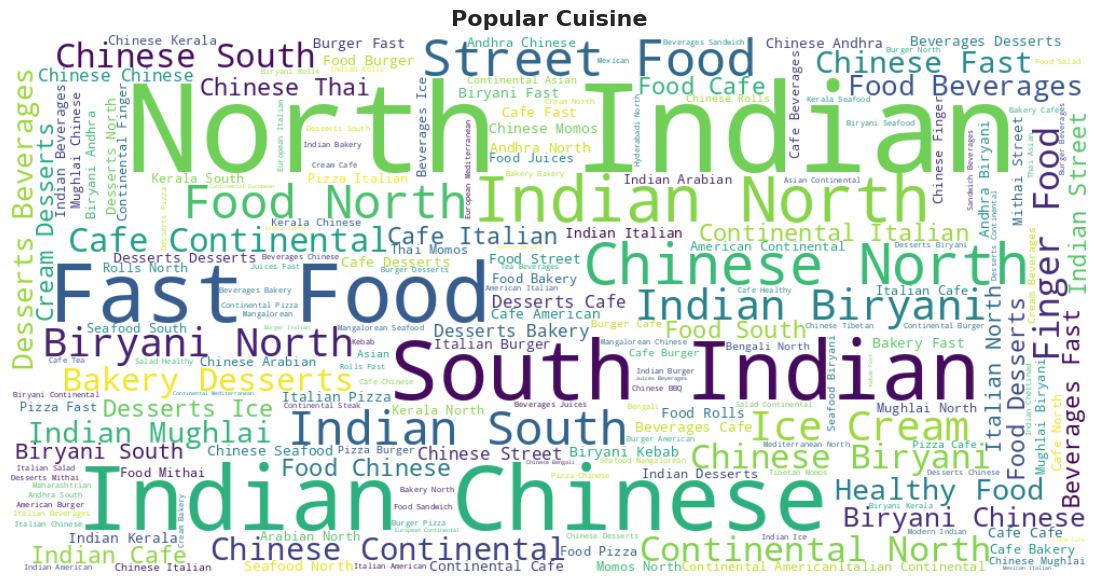

In [ ]:
!pip install wordcloud
from wordcloud import WordCloud

# Join all cuisine names into one text
text = ' '.join(all_cuisines.dropna())

# Create word cloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(text)

# Plot
plt.figure(figsize=(15,7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title(
    "Popular Cuisine",
    fontsize=16,
    fontweight='bold'
)

plt.show()

### Observation

The largest words in the word cloud represent the most frequently occurring cuisine keywords within the dataset. North Indian, Chinese, South Indian, and Fast Food appear prominently.

### Business Insight

The word cloud reinforces the findings from the cuisine analysis, highlighting the cuisines that dominate Bengaluru's restaurant landscape and influence customer dining choices.



---



## Business Question 7

How are the numerical variables related to each other?

In [ ]:
numeric_cols = ['rate', 'votes', 'approx_cost(for two people)', 'success_score']

correlation_matrix = df[numeric_cols].corr()

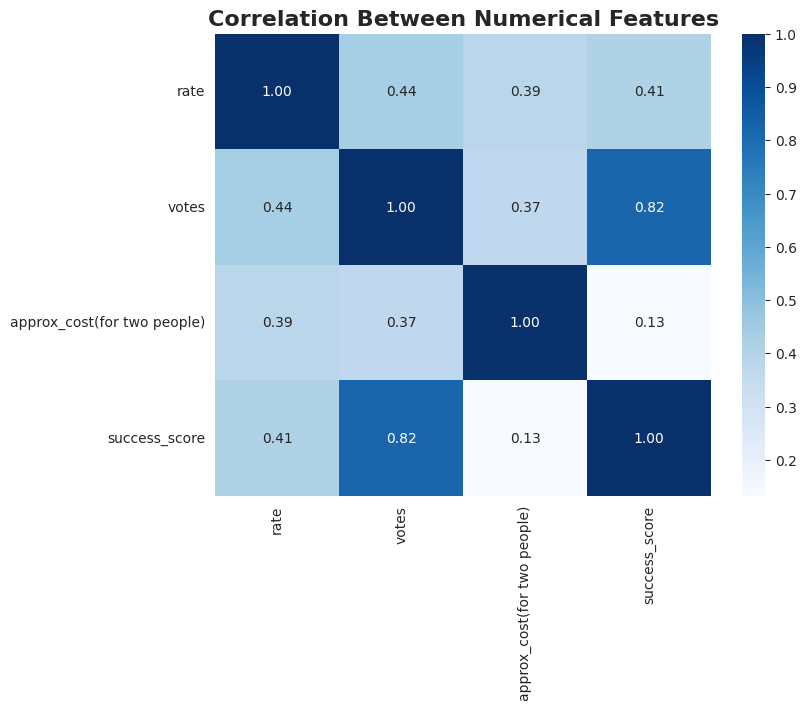

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='Blues',
    fmt='.2f'
)

plt.title(
    'Correlation Between Numerical Features',
    fontsize=16,
    fontweight='bold'
)

plt.show()

### Observation

The heatmap shows the strength and direction of relationships between numerical variables such as ratings, votes, cost, and success score. Some variables display stronger positive relationships than others.

### Business Insight

Understanding these relationships helps identify which factors have the greatest influence on restaurant performance and customer engagement.


---



## Business Question 8

Which locations have the highest concentration of restaurants in Bengaluru?

/tmp/ipykernel_1411/2770986478.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


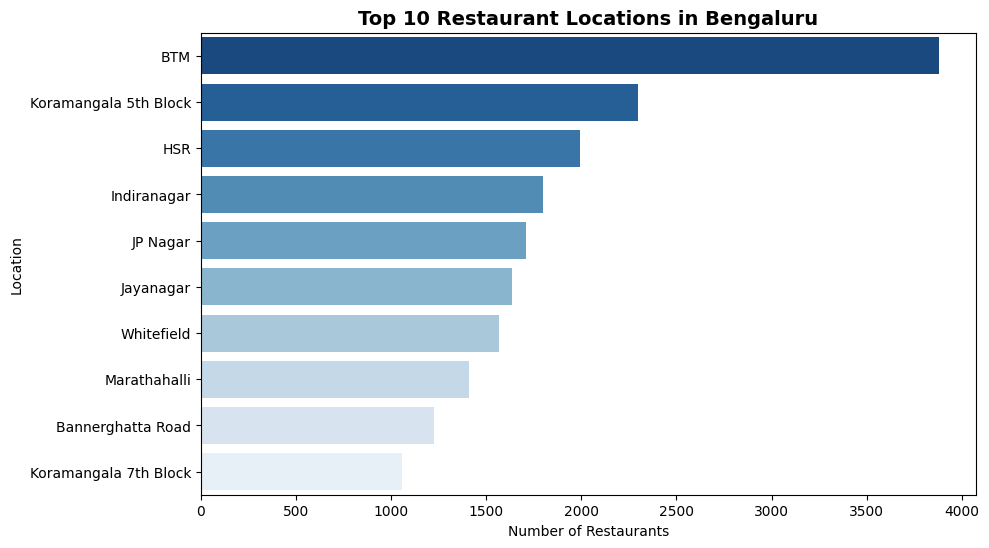

In [ ]:
top_locations = df['location'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(
    x=top_locations.values,
    y=top_locations.index,
    palette='Blues_r'
)

plt.title('Top 10 Restaurant Locations in Bengaluru', fontsize=14, fontweight='bold')
plt.xlabel('Number of Restaurants')
plt.ylabel('Location')
plt.show()

### Observation

A small number of locations contain a large proportion of Bengaluru's restaurants. Areas such as BTM, Koramangala, and HSR Layout appear among the most active restaurant hubs.

### Business Insight

Restaurant businesses tend to cluster in high-demand commercial and residential areas where customer traffic is strong. These locations represent major food-service markets within the city.


---



## Business Question 9

Which restaurant formats are most common in Bengaluru?


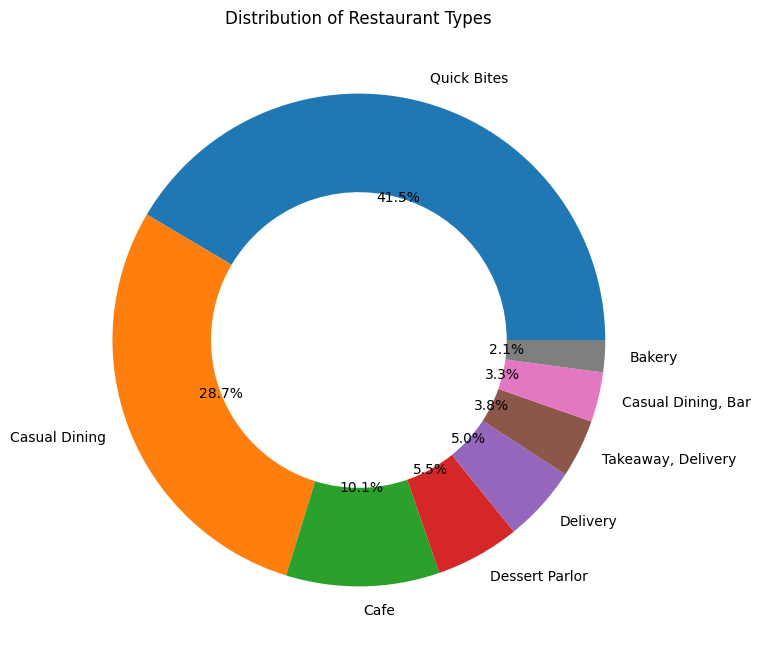

In [ ]:
top_rest_types = df['rest_type'].value_counts().head(8)

plt.figure(figsize=(8,8))

plt.pie(
    top_rest_types,
    labels=top_rest_types.index,
    autopct='%1.1f%%',
    wedgeprops={'width':0.4}
)

plt.title('Distribution of Restaurant Types')
plt.show()

### Observation

Quick Bites and Casual Dining dominate the restaurant landscape, significantly outnumbering premium dining formats.

### Business Insight

Customers appear to favor convenience and affordability, making quick-service and casual dining formats highly popular business models.


---



## Business Question 10

Which cuisine categories receive the highest customer ratings?

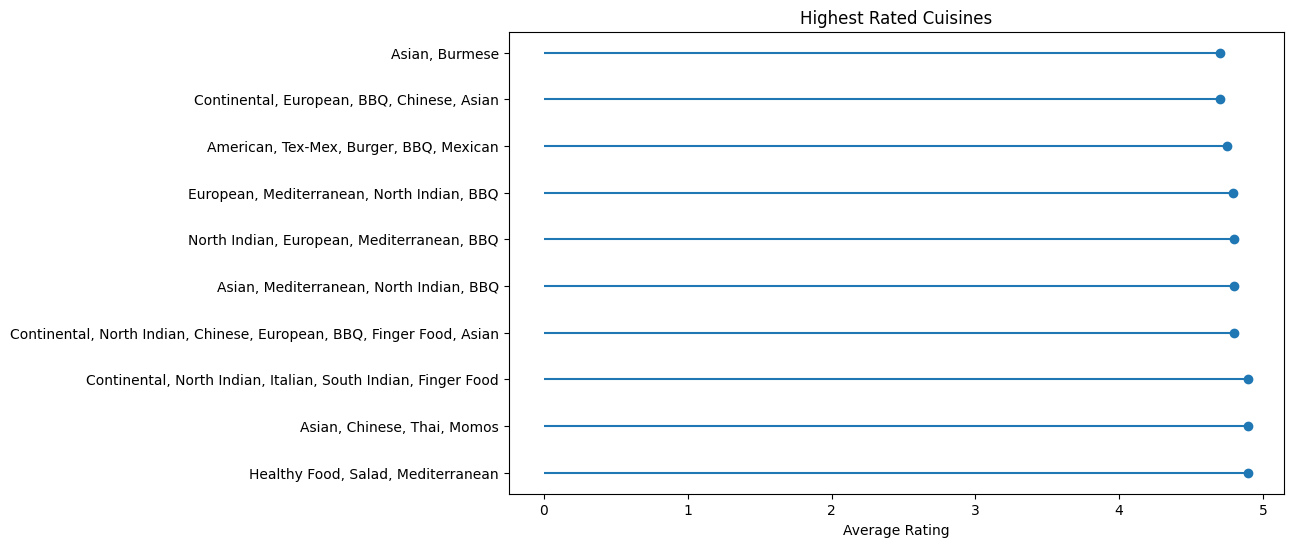

In [ ]:
top_cuisines = (
    df.groupby('cuisines')['rate']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

plt.hlines(
    y=top_cuisines.index,
    xmin=0,
    xmax=top_cuisines.values
)

plt.plot(
    top_cuisines.values,
    top_cuisines.index,
    "o"
)

plt.title("Highest Rated Cuisines")
plt.xlabel("Average Rating")
plt.show()

### Observation

Certain cuisine categories consistently achieve higher average ratings than others, indicating stronger customer satisfaction.

### Business Insight

Cuisine selection can significantly influence restaurant success. High-performing cuisines may represent attractive opportunities for future restaurant businesses.


---



# 📌 Key Business Insights

1. Most restaurants receive ratings between 3.5 and 4.0, indicating a competitive market with generally positive customer experiences.

2. Higher pricing does not guarantee higher customer ratings.

3. North Indian cuisine dominates Bengaluru's restaurant industry.

4. Quick Bites and Casual Dining are the most common restaurant formats.

5. Restaurant activity is concentrated in a few major locations such as BTM and Koramangala.

6. Online ordering alone has limited impact on customer ratings.

7. Customer satisfaction appears to be influenced by multiple factors beyond pricing.

# **Dashboard**





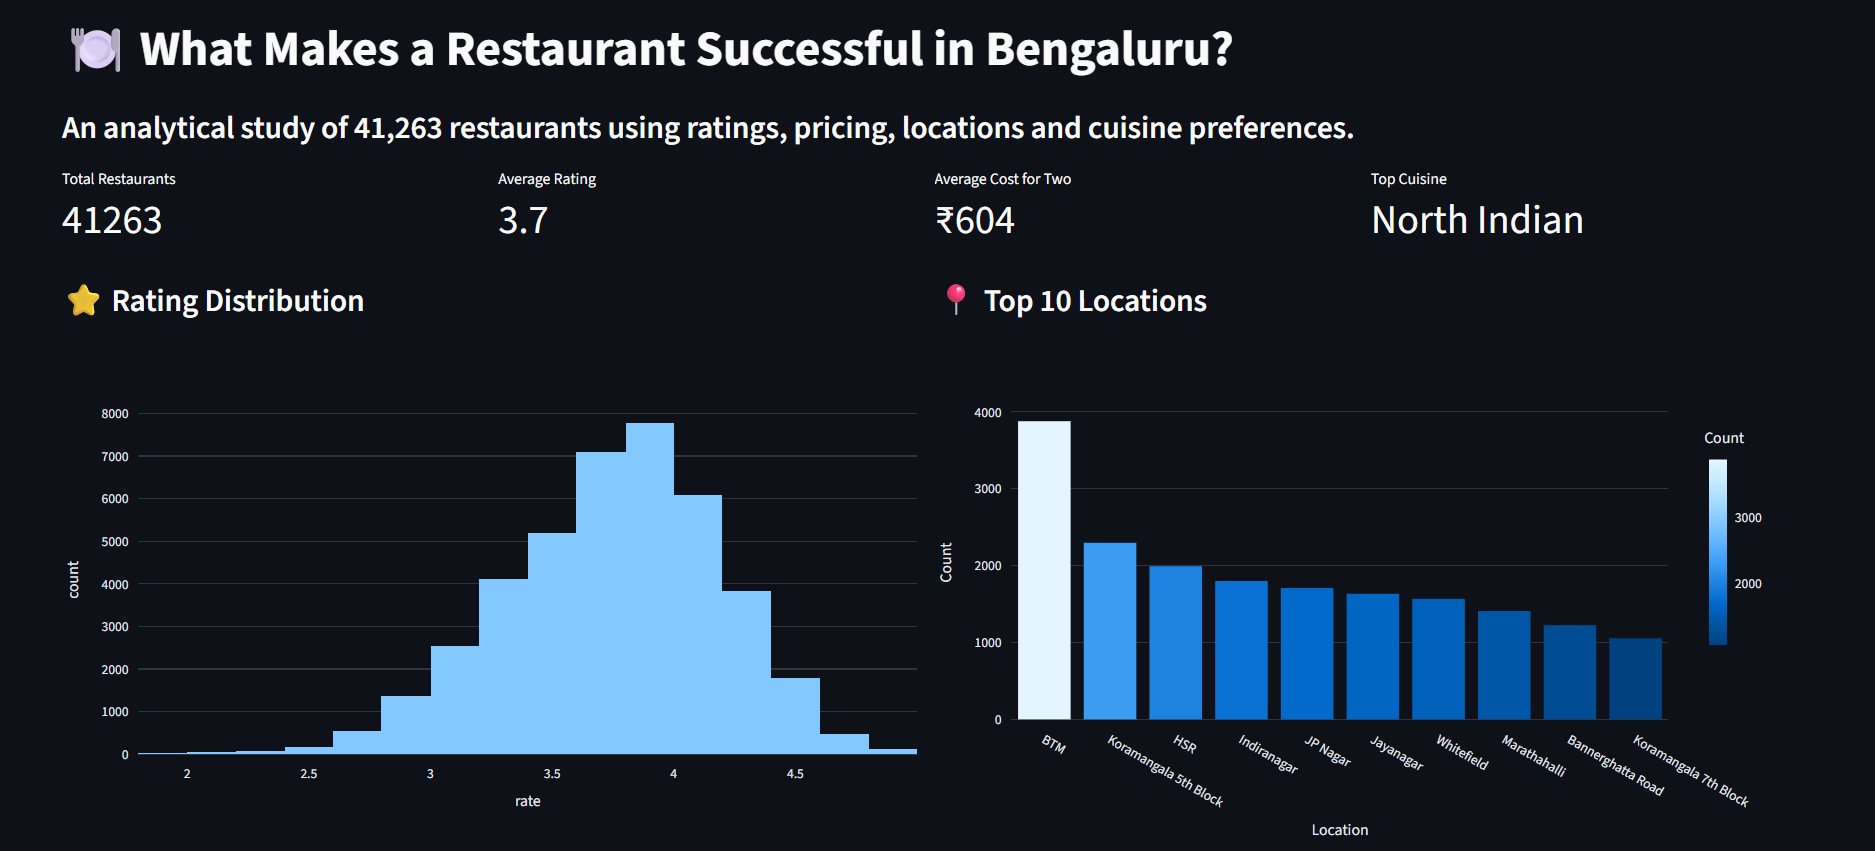

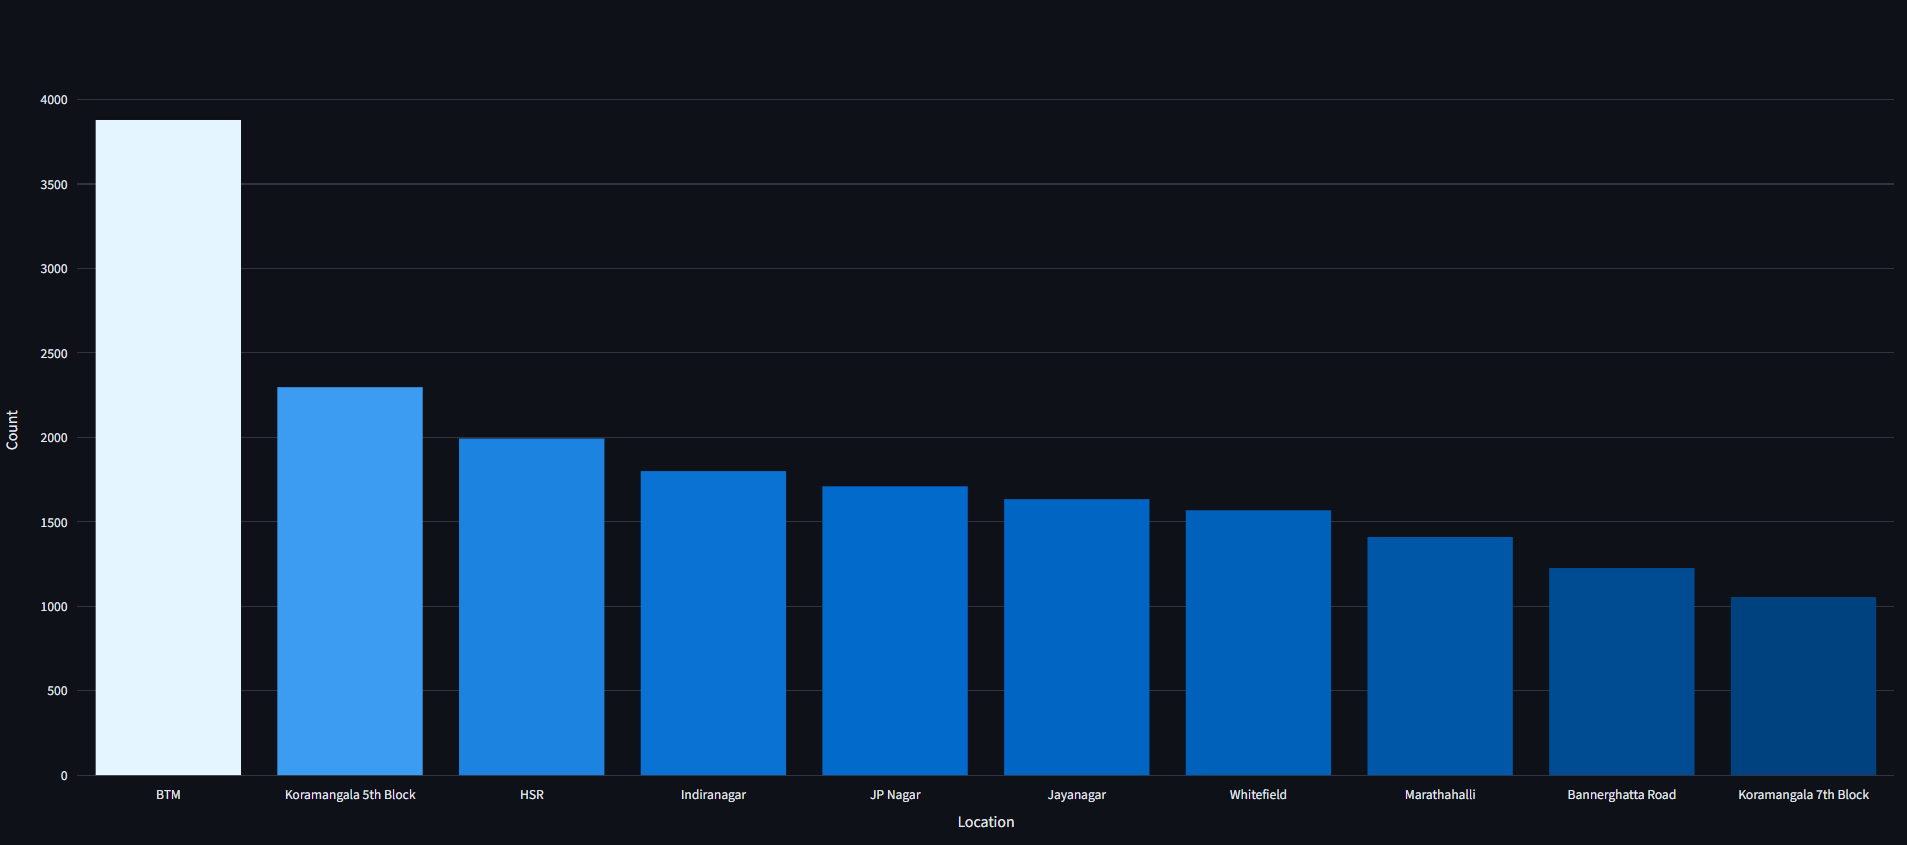

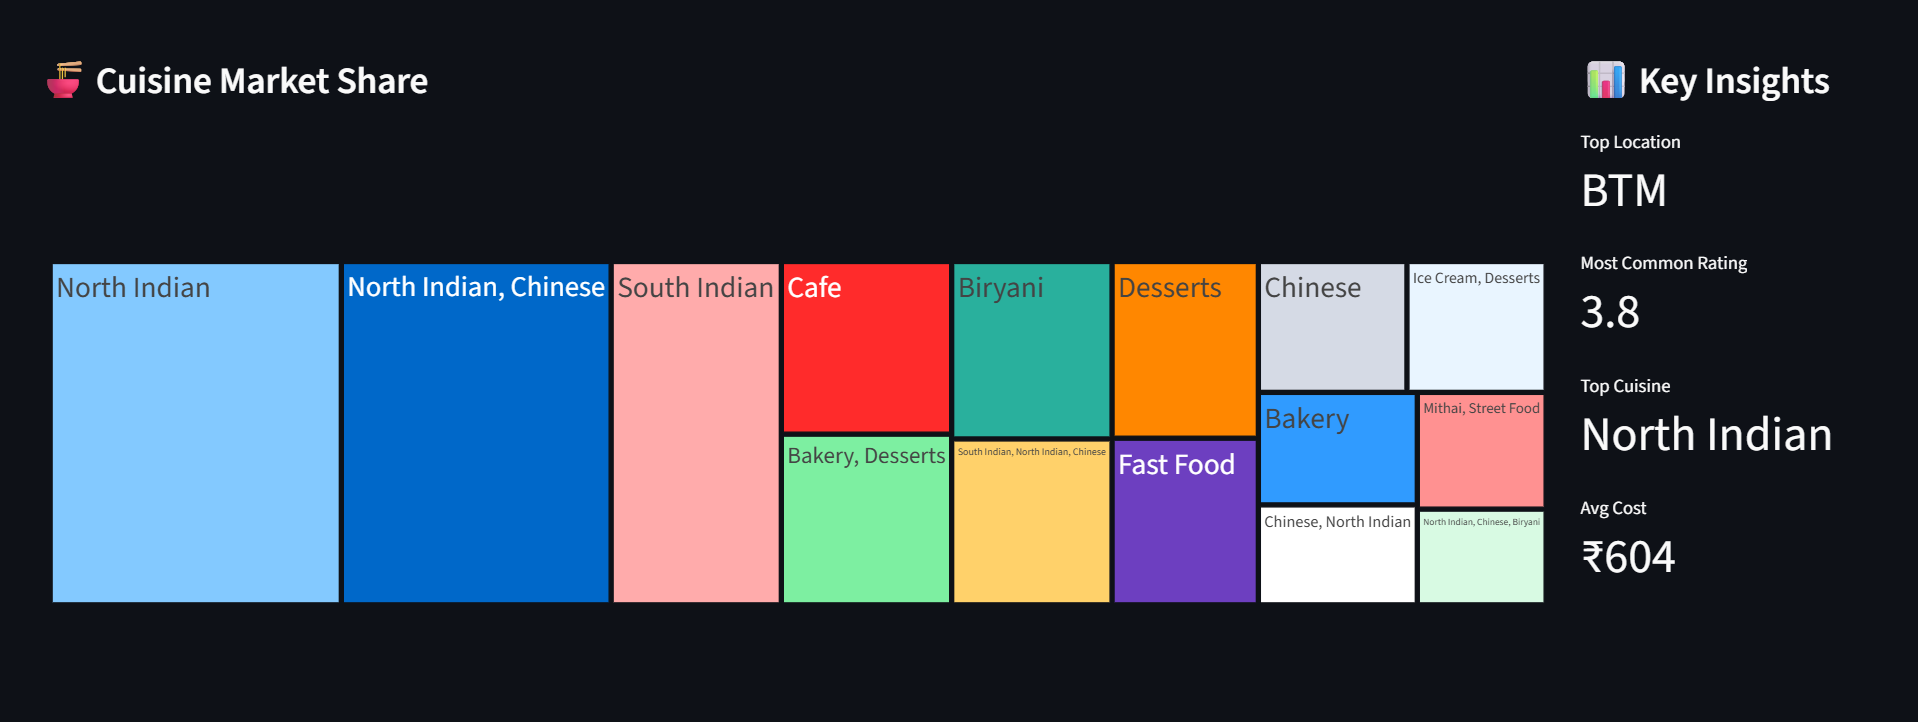



---



# 🎯 Conclusion

This project analyzed over 50,000 restaurant records from Bengaluru to identify the factors influencing restaurant performance and customer satisfaction.

Through data cleaning, feature engineering, exploratory data analysis, and visualization, valuable insights were obtained regarding pricing patterns, cuisine popularity, customer ratings, restaurant locations, and business models.

The analysis demonstrates how data analytics can transform raw restaurant data into meaningful business intelligence, helping restaurant owners and decision-makers better understand market trends and customer preferences.


---



---

